# Tech Challenge — Fase 2 · Demonstração

Otimização dos modelos de diagnóstico da Fase 1 com **algoritmo genético** e interpretação dos resultados com **LLM**.

> Projeto educacional de apoio à triagem. Não substitui a avaliação de profissionais de saúde.

In [1]:
import os, sys, json, warnings
sys.path.insert(0, os.path.abspath('..'))
os.chdir(os.path.abspath('..'))
warnings.filterwarnings('ignore')
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 160)

## 1. Dados — mesmo split da Fase 1

In [2]:
from src.data import load_split
data = load_split()
print('treino:', data.X_train.shape, '| teste:', data.X_test.shape, '| malignos no teste:', int(data.y_test.sum()))

treino: (455, 30) | teste: (114, 30) | malignos no teste: 42


## 2. Codificação: cromossomo → hiperparâmetros

Cada indivíduo é um vetor em [0,1]^d; cada gene é decodificado conforme o seu tipo.

In [3]:
import numpy as np
from src.spaces import SPACES
space = SPACES['random_forest']
chrom = np.random.default_rng(0).random(space.size)
print('cromossomo:', chrom.round(3))
space.decode(chrom)

cromossomo: [0.637 0.27  0.041 0.017 0.813 0.913 0.607 0.729 0.544]


{'n_estimators': 209,
 'max_depth': 5,
 'min_samples_split': 3,
 'min_samples_leaf': 1,
 'max_features': 0.8,
 'criterion': 'entropy',
 'class_weight': 'balanced',
 'bootstrap': False,
 'threshold': 0.53}

## 3. Rodando um AG pequeno ao vivo (Regressão Logística)

In [4]:
from src.fitness import CVFitness
from src.ga import GAConfig, GeneticAlgorithm
from src.models import BASELINE_PARAMS

fitness = CVFitness('logistic_regression', data.X_train, data.y_train)
print('fitness do modelo original:', round(fitness(BASELINE_PARAMS['logistic_regression'])[0], 4))
cfg = GAConfig(population_size=10, generations=6, crossover='blx', mutation_rate=0.15, seed=1)
result = GeneticAlgorithm(SPACES['logistic_regression'], fitness, cfg).run()
pd.DataFrame([{'geração': h.generation, 'melhor': round(h.best_fitness, 4), 'média': round(h.mean_fitness, 4),
               'diversidade': round(h.diversity, 3)} for h in result.history])

fitness do modelo original: 0.9671


,geração,melhor,média,diversidade
0,0,0.9739,0.9090,0.276
1,1,0.9739,0.9667,0.208
2,2,0.9739,0.9708,0.153
3,3,0.9739,0.9727,0.086
4,4,0.9739,0.9738,0.015
5,5,0.9739,0.9729,0.031
6,6,0.9739,0.9735,0.047


In [5]:
result.best_params, round(result.best_fitness, 4)

({'C': 64.3111,
  'l1_ratio': 0.72,
  'class_weight': 'balanced',
  'threshold': 0.37},
 0.9739)

## 4. Resultados completos dos experimentos

Gerados por `python -m scripts.run_experiments` (5 configurações do AG + busca aleatória por modelo).

In [6]:
res = json.load(open('reports/results/experiments.json'))
rows = []
for model, r in res['models'].items():
    allr = {'original': r['baseline'], **r['experiments'], 'busca_aleatoria': r['random_search']}
    for name, rec in allr.items():
        t = rec['test_metrics']
        rows.append({'modelo': model, 'config': name, 'cv_fitness': round(rec['cv_fitness'], 4),
                     'cv5x3': round(rec['robust_cv']['fitness']['mean'], 4), 'recall': round(t['recall'], 3),
                     'f1': round(t['f1'], 3), 'auc': round(t['roc_auc'], 3), 'FN': t['false_negatives'],
                     'FP': t['false_positives']})
pd.DataFrame(rows)

,modelo,config,cv_fitness,cv5x3,recall,f1,auc,FN,FP
0,logistic_regression,original,0.9671,0.9659,0.952,0.964,0.995,2,1
1,logistic_regression,E1_pop_pequena,0.9771,0.9703,0.976,0.965,0.997,1,2
2,logistic_regression,E2_blx_torneio,0.9770,0.9699,0.952,0.952,0.994,2,2
3,logistic_regression,E3_roleta_um_ponto,0.9780,0.9678,0.976,0.943,0.997,1,4
4,logistic_regression,E4_alta_mutacao,0.9763,0.9694,0.976,0.976,0.997,1,1
5,logistic_regression,E5_semeado_baseline,0.9770,0.9699,0.952,0.952,0.994,2,2
6,logistic_regression,busca_aleatoria,0.9763,0.9703,0.976,0.976,0.997,1,1
7,random_forest,original,0.9621,0.9516,0.929,0.963,0.997,3,0
8,random_forest,E1_pop_pequena,0.9676,0.9606,0.929,0.951,0.998,3,1
9,random_forest,E2_blx_torneio,0.9659,0.9579,0.929,0.951,0.996,3,1


In [7]:
print('Selecionado:', res['selected']['model'], '/', res['selected']['source'])
res['selected']['params']

Selecionado: logistic_regression / E1_pop_pequena


{'C': 0.5928, 'l1_ratio': 0.11, 'class_weight': None, 'threshold': 0.26}

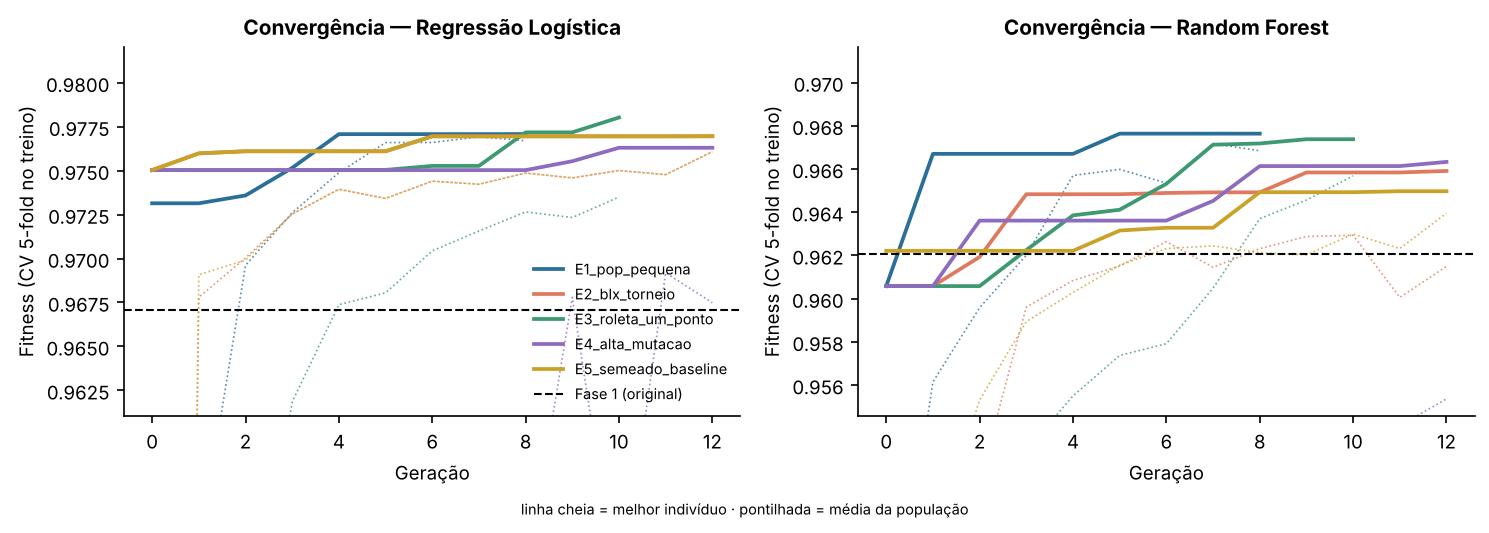

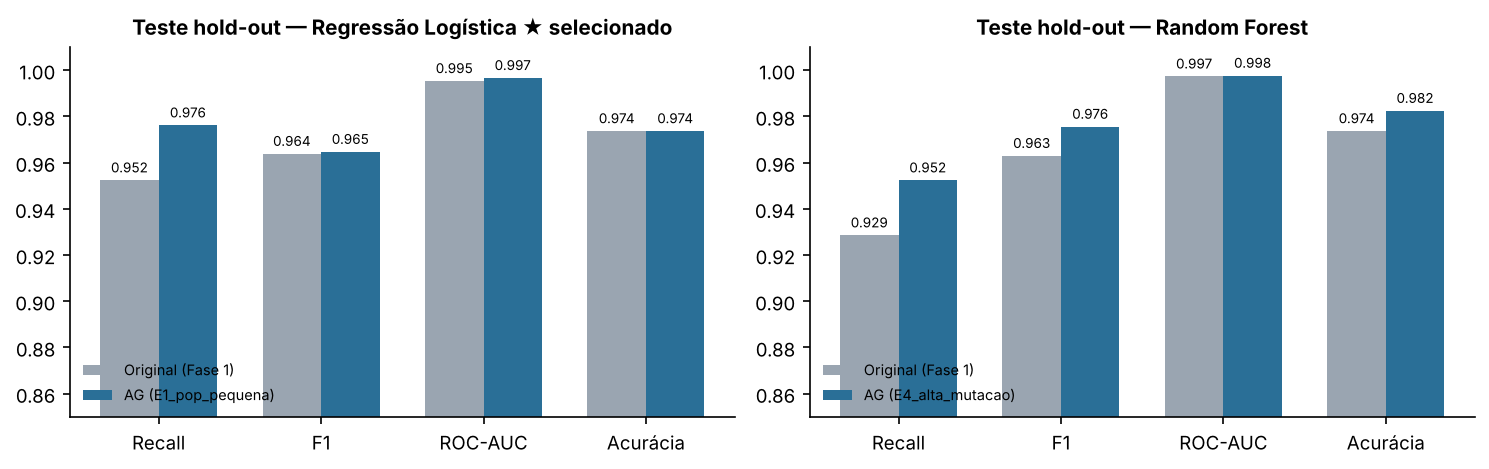

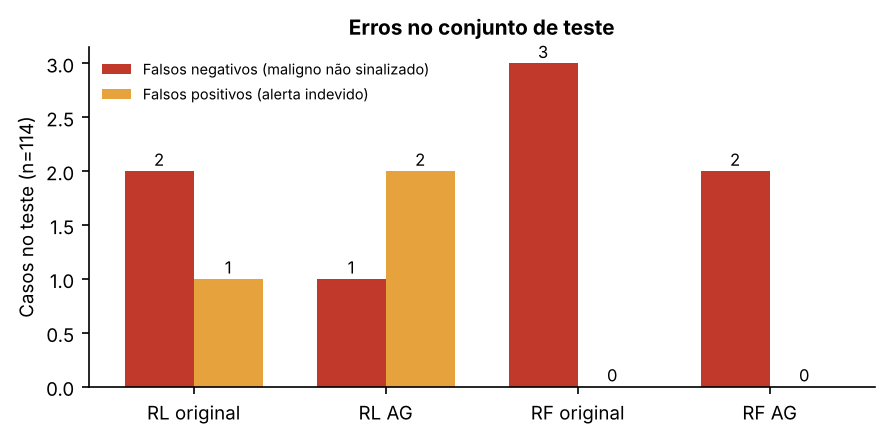

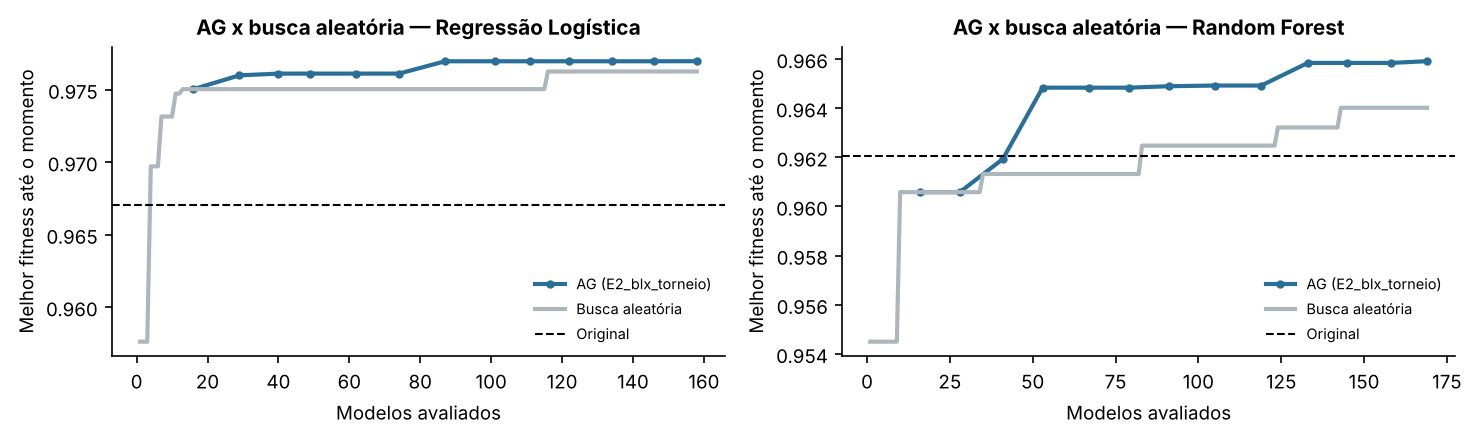

In [8]:
for f in ['convergencia_ag.png', 'comparativo_teste.png', 'erros_teste.png', 'ag_vs_busca_aleatoria.png']:
    display(Image(f'reports/figures/{f}'))

## 5. Interpretação com LLM

Defina `LLM_PROVIDER` (groq, ollama, openai, anthropic) no `.env`. Sem chave, o provedor `offline` é usado.

In [9]:
import joblib
from src.llm import DiagnosisInterpreter, get_provider
model = joblib.load('models/best_model.joblib')
card = json.load(open('models/model_card.json'))
provider = get_provider(os.getenv('LLM_PROVIDER', 'offline'))
interp = DiagnosisInterpreter(model, card, provider)
caso = data.X_test[data.y_test == 1].iloc[[0]]
out = interp.explain_case(caso)
print(out.text)
print('\n[provedor:', out.provider, '| fallback:', out.used_fallback, ']')

Resumo: O modelo estimou probabilidade de malignidade de 100.0%, acima do limiar de decisão de 0.26. Faixa de risco: alto.

Fatores relevantes:
• raio (erro-padrão): 1.004 (média benignos 0.2861, média malignos 0.6208) — aumenta o risco
• pontos côncavos (média): 0.131 (média benignos 0.0253, média malignos 0.0888) — aumenta o risco
• raio (pior valor): 25.58 (média benignos 13.4114, média malignos 21.2806) — aumenta o risco

Confiabilidade: No conjunto de teste, o modelo (Regressão Logística, otimizado por algoritmo genético) identificou 97.6% dos casos malignos (recall), com 1 falso(s) negativo(s) em 114 amostras.

Recomendação: Priorizar avaliação médica e considerar confirmação por exame de imagem e biópsia, conforme julgamento clínico.

Limitações: Estimativa estatística baseada em medidas morfológicas de núcleos celulares; não considera histórico clínico, imagem ou outros exames.

Aviso: Apoio à decisão: não confirma nem descarta câncer e não substitui a avaliação médica.

[prove

### Contexto numérico enviado à LLM (grounding)

In [10]:
pd.DataFrame(out.context['fatores_principais'])

,atributo,nome,valor,mediana_treino,impacto,direcao,media_benignos,media_malignos
0,radius_se,raio (erro-padrão),1.004,0.3274,0.0,aumenta o risco,0.2861,0.6208
1,concave points_mean,pontos côncavos (média),0.131,0.0333,0.0,aumenta o risco,0.0253,0.0888
2,radius_worst,raio (pior valor),25.580,14.9200,0.0,aumenta o risco,13.4114,21.2806
3,area_worst,área (pior valor),2010.000,683.4000,0.0,aumenta o risco,561.8123,1441.7206
4,area_se,área (erro-padrão),137.900,24.8700,0.0,aumenta o risco,21.3519,74.6864


### Avaliação automática da resposta

In [11]:
from src.llm.evaluation import evaluate_interpretation
evaluate_interpretation(out)

{'formato': 1.0,
 'fidelidade': 1.0,
 'cobertura': 1.0,
 'coerencia': 1.0,
 'seguranca': 1.0,
 'legibilidade': 1.0,
 'score_geral': 1.0,
 'numeros_inventados': [],
 'violacoes': [],
 'latencia_s': 0.0,
 'fallback': False,
 'palavras': 141}

### Insights de desempenho para a equipe clínica

In [12]:
print(interp.explain_performance(res).text)

Resumo: O modelo Regressão Logística otimizado por algoritmo genético obteve recall de 97.6% contra 95.2% do modelo original no teste.

Insights:
• Falsos negativos no teste: 2 (original) → 1 (otimizado).
• Falsos positivos no teste: 1 (original) → 2 (otimizado).
• ROC-AUC: 0.995 (original) → 0.997 (otimizado).

Impacto clínico: Menos casos malignos deixariam de ser sinalizados na triagem.

Recomendação: Validar o modelo em dados externos antes de qualquer uso assistencial.

Aviso: Métricas obtidas em base pública e amostra pequena; não substituem validação clínica.
